In [10]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

PASTA_IMAGENS = Path("images")
PASTA_IMAGENS.mkdir(exist_ok=True)


def fmt_pace_eixo(val, _pos=None):
  if pd.isna(val) or val <= 0:
    return ""
  total_seg = int(round(val * 60))
  minutos, segundos = divmod(total_seg, 60)
  return f"{minutos}:{segundos:02d}"


# 1. Carrega os 3 CSVs sincronizados pelo ETL
df_c = pd.read_csv("df_corridas.csv")
df_km_raw = pd.read_csv("df_por_km.csv")
df_100m_raw = pd.read_csv("df_por_100m.csv")

df_c["data"] = pd.to_datetime(df_c["data"], format="mixed")

# 2. Mantém apenas as corridas válidas definidas no Notebook 01
df_c_validas = df_c[
    (df_c["modalidade"] == "Rua")
    & (df_c["distancia_km"] >= 2.0)
    & (df_c["pace_dec"] < 8.0)
].copy()

ids_validos = set(df_c_validas["record_id"])
mapa_ano = df_c_validas.set_index("record_id")["ano"]
mapa_dist_total = df_c_validas.set_index("record_id")["distancia_km"]
mapa_ganho_total = df_c_validas.set_index("record_id")["ganho_elev_total_m"]

# 3. Prepara base Meso (df_por_km): apenas quilômetros cheios (>= 850m)
df_km = df_km_raw[
    (df_km_raw["record_id"].isin(ids_validos))
    & (df_km_raw["distancia_m"] >= 850)
    & (df_km_raw["pace_dec"] < 8.5)
].copy()

df_km["ano"] = df_km["record_id"].map(mapa_ano)
df_km["dist_total_km"] = df_km["record_id"].map(mapa_dist_total)
df_km["pct_concluido"] = (df_km["km"] / df_km["dist_total_km"] * 100).clip(0, 100)

# 4. Prepara base Micro (df_por_100m): filtra sobras curtas, caminhadas pontuais e ruído de altitude
df_100m = df_100m_raw[
    (df_100m_raw["record_id"].isin(ids_validos))
    & (df_100m_raw["distancia_m"] >= 70)
    & (df_100m_raw["pace_dec"] <= 8.5)
    & (df_100m_raw["inclinacao_pct"].between(-20.0, 20.0))
].copy()

df_100m["ano"] = df_100m["record_id"].map(mapa_ano)
df_100m["dist_total_km"] = df_100m["record_id"].map(mapa_dist_total)
df_100m["ganho_elev_total_m"] = df_100m["record_id"].map(mapa_ganho_total)
df_100m["pct_concluido"] = (
    df_100m["dist_acum_m"] / (df_100m["dist_total_km"] * 1000.0) * 100.0
).clip(0, 100)

# Discretiza inclinação em 6 faixas físicas
ordem_inc = [
    "Descida Forte (<-4%)",
    "Descida Leve (-4% a -1.5%)",
    "Plano (-1.5% a +1.5%)",
    "Subida Leve (+1.5% a +3.5%)",
    "Subida Moderada (+3.5% a +6%)",
    "Subida Forte (>+6%)",
]
df_100m["faixa_inclinacao"] = pd.cut(
    df_100m["inclinacao_pct"],
    bins=[-20.1, -4.0, -1.5, 1.5, 3.5, 6.0, 20.1],
    labels=ordem_inc,
)
df_100m["faixa_inclinacao"] = pd.Categorical(
    df_100m["faixa_inclinacao"], categories=ordem_inc, ordered=True
)

print(
    f"Base Meso (km cheios): {len(df_km)} splits em {df_km['record_id'].nunique()} corridas"
)
print(
    f"Base Micro (100m):     {len(df_100m)} trechos em {df_100m['record_id'].nunique()} corridas"
)

Base Meso (km cheios): 1092 splits em 198 corridas
Base Micro (100m):     10962 trechos em 197 corridas


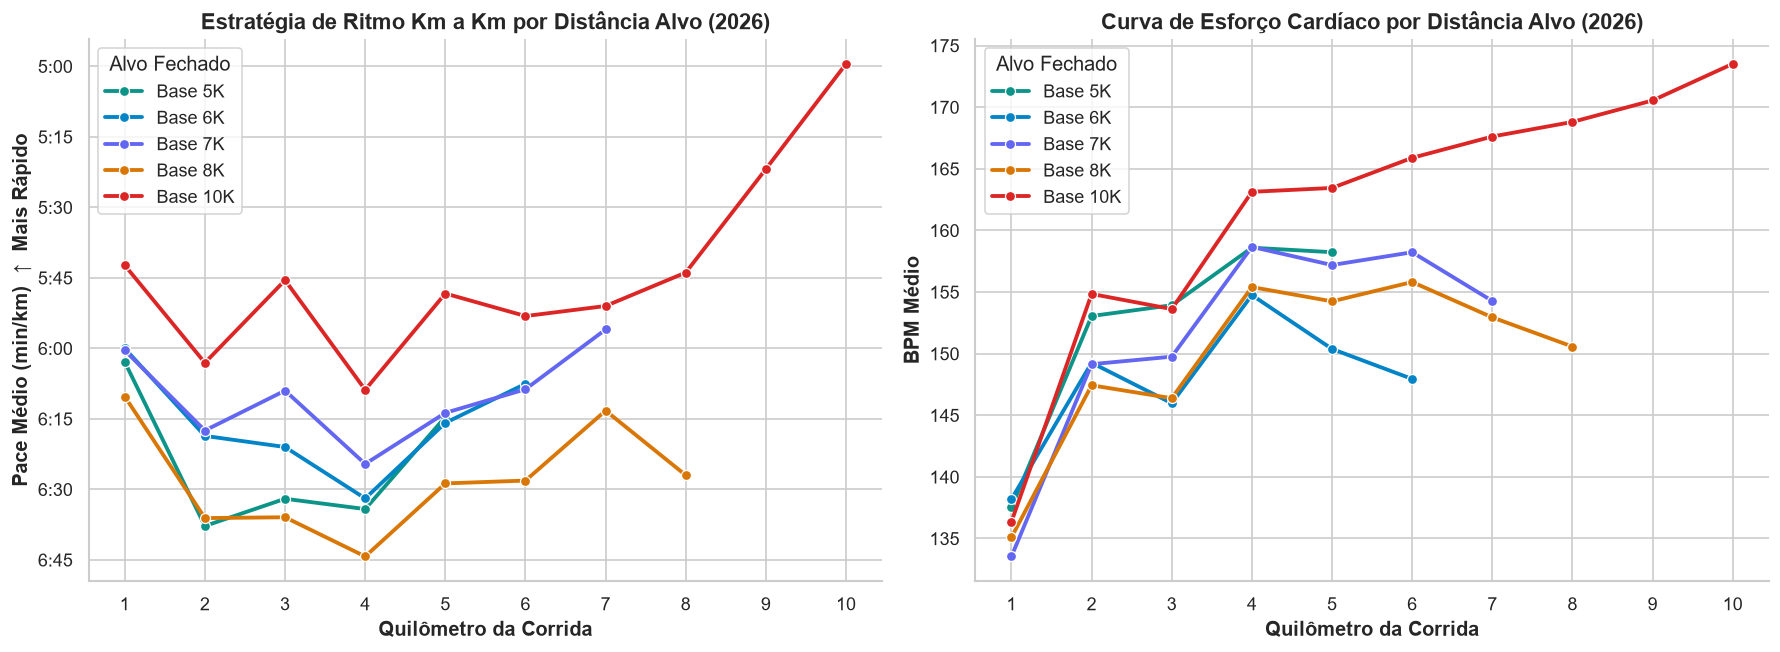

In [11]:
bases_foco = ["Base 5K", "Base 6K", "Base 7K", "Base 8K", "Base 10K"]
paleta_bases = {
    "Base 5K": "#0D9488",
    "Base 6K": "#0284C7",
    "Base 7K": "#6366F1",
    "Base 8K": "#D97706",
    "Base 10K": "#DC2626",
}

df_km_26 = df_km[
    (df_km["ano"] == 2026) & (df_km["faixa_distancia"].isin(bases_foco))
].copy()

# Agrupa por faixa e km exigindo ao menos 3 corridas no ponto
curva_km = (
    df_km_26.groupby(["faixa_distancia", "km"])
    .agg(
        n=("record_id", "count"),
        pace_medio=("pace_dec", "mean"),
        bpm_medio=("bpm_medio", "mean"),
    )
    .reset_index()
    .query("n >= 3")
)

# Garante ordem da legenda e evita conflito de categorias vazias no Seaborn
curva_km["faixa_distancia"] = pd.Categorical(
    curva_km["faixa_distancia"], categories=bases_foco, ordered=True
)
curva_km = curva_km.sort_values(["faixa_distancia", "km"])
curva_km["faixa_str"] = curva_km["faixa_distancia"].astype(str)

fig, (ax_pace, ax_bpm) = plt.subplots(1, 2, figsize=(15, 5.6))

sns.lineplot(
    data=curva_km,
    x="km",
    y="pace_medio",
    hue="faixa_str",
    hue_order=bases_foco,
    palette=paleta_bases,
    marker="o",
    linewidth=2.3,
    ax=ax_pace,
)
ax_pace.invert_yaxis()
ax_pace.yaxis.set_major_formatter(FuncFormatter(fmt_pace_eixo))
ax_pace.set_xticks(range(1, int(curva_km["km"].max()) + 1))
ax_pace.set_xlabel("Quilômetro da Corrida", fontweight="bold")
ax_pace.set_ylabel("Pace Médio (min/km)  ↑  Mais Rápido", fontweight="bold")
ax_pace.set_title("Estratégia de Ritmo Km a Km por Distância Alvo (2026)")
ax_pace.legend(title="Alvo Fechado", frameon=True)

sns.lineplot(
    data=curva_km,
    x="km",
    y="bpm_medio",
    hue="faixa_str",
    hue_order=bases_foco,
    palette=paleta_bases,
    marker="o",
    linewidth=2.3,
    ax=ax_bpm,
)
ax_bpm.set_xticks(range(1, int(curva_km["km"].max()) + 1))
ax_bpm.set_xlabel("Quilômetro da Corrida", fontweight="bold")
ax_bpm.set_ylabel("BPM Médio", fontweight="bold")
ax_bpm.set_title("Curva de Esforço Cardíaco por Distância Alvo (2026)")
ax_bpm.legend(title="Alvo Fechado", frameon=True)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "05_estrategia_km_por_distancia_2026.png")
plt.show()

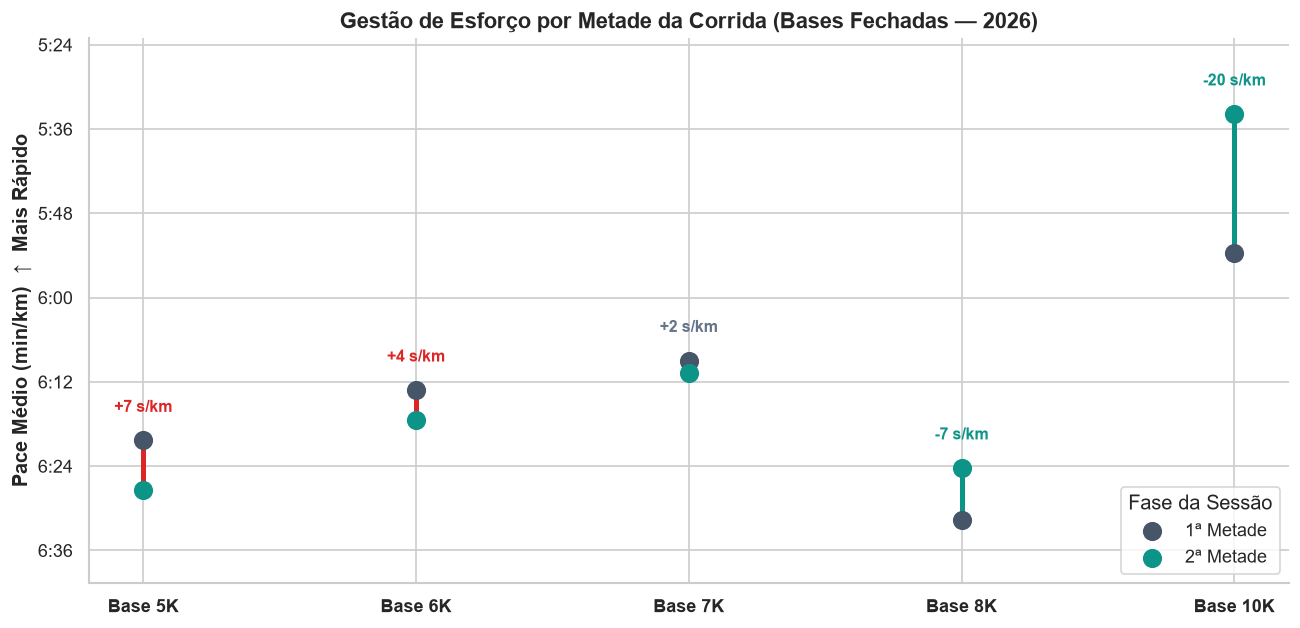

In [12]:
# Substitui apenas a parte de plotagem da Célula 3 (Gráfico 06)
fig, ax = plt.subplots(figsize=(11, 5.4))

for idx, faixa in enumerate(bases_foco):
  p1 = piv_split.loc[faixa, ("pace_medio", "1ª Metade")]
  p2 = piv_split.loc[faixa, ("pace_medio", "2ª Metade")]
  diff_s = piv_split.loc[faixa, "diff_pace_seg_km"]

  cor_linha = "#DC2626" if diff_s > 3 else ("#0D9488" if diff_s < -3 else "#64748B")
  ax.plot([idx, idx], [p1, p2], color=cor_linha, linewidth=3, zorder=2)

  sinal = "+" if diff_s > 0 else ""
  topo_y = min(p1, p2)  # Como o eixo Y é invertido, o menor pace fica mais alto
  ax.text(
      idx,
      topo_y - 0.06,
      f"{sinal}{diff_s:.0f} s/km",
      ha="center",
      va="bottom",
      fontweight="bold",
      fontsize=9.5,
      color=cor_linha,
  )

ax.scatter(
    range(len(bases_foco)),
    [piv_split.loc[f, ("pace_medio", "1ª Metade")] for f in bases_foco],
    color="#475569",
    s=110,
    zorder=3,
    label="1ª Metade",
)
ax.scatter(
    range(len(bases_foco)),
    [piv_split.loc[f, ("pace_medio", "2ª Metade")] for f in bases_foco],
    color="#0D9488",
    s=110,
    zorder=3,
    label="2ª Metade",
)

y_min = resumo_split["pace_medio"].min() - 0.18
y_max = resumo_split["pace_medio"].max() + 0.15
ax.set_ylim(y_max, y_min)
ax.yaxis.set_major_formatter(FuncFormatter(fmt_pace_eixo))
ax.set_xticks(range(len(bases_foco)))
ax.set_xticklabels(bases_foco, fontweight="bold")
ax.set_ylabel("Pace Médio (min/km)  ↑  Mais Rápido", fontweight="bold")
ax.set_title("Gestão de Esforço por Metade da Corrida (Bases Fechadas — 2026)")
ax.legend(title="Fase da Sessão", frameon=True, loc="lower right")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "06_split_primeira_vs_segunda_metade.png")
plt.show()

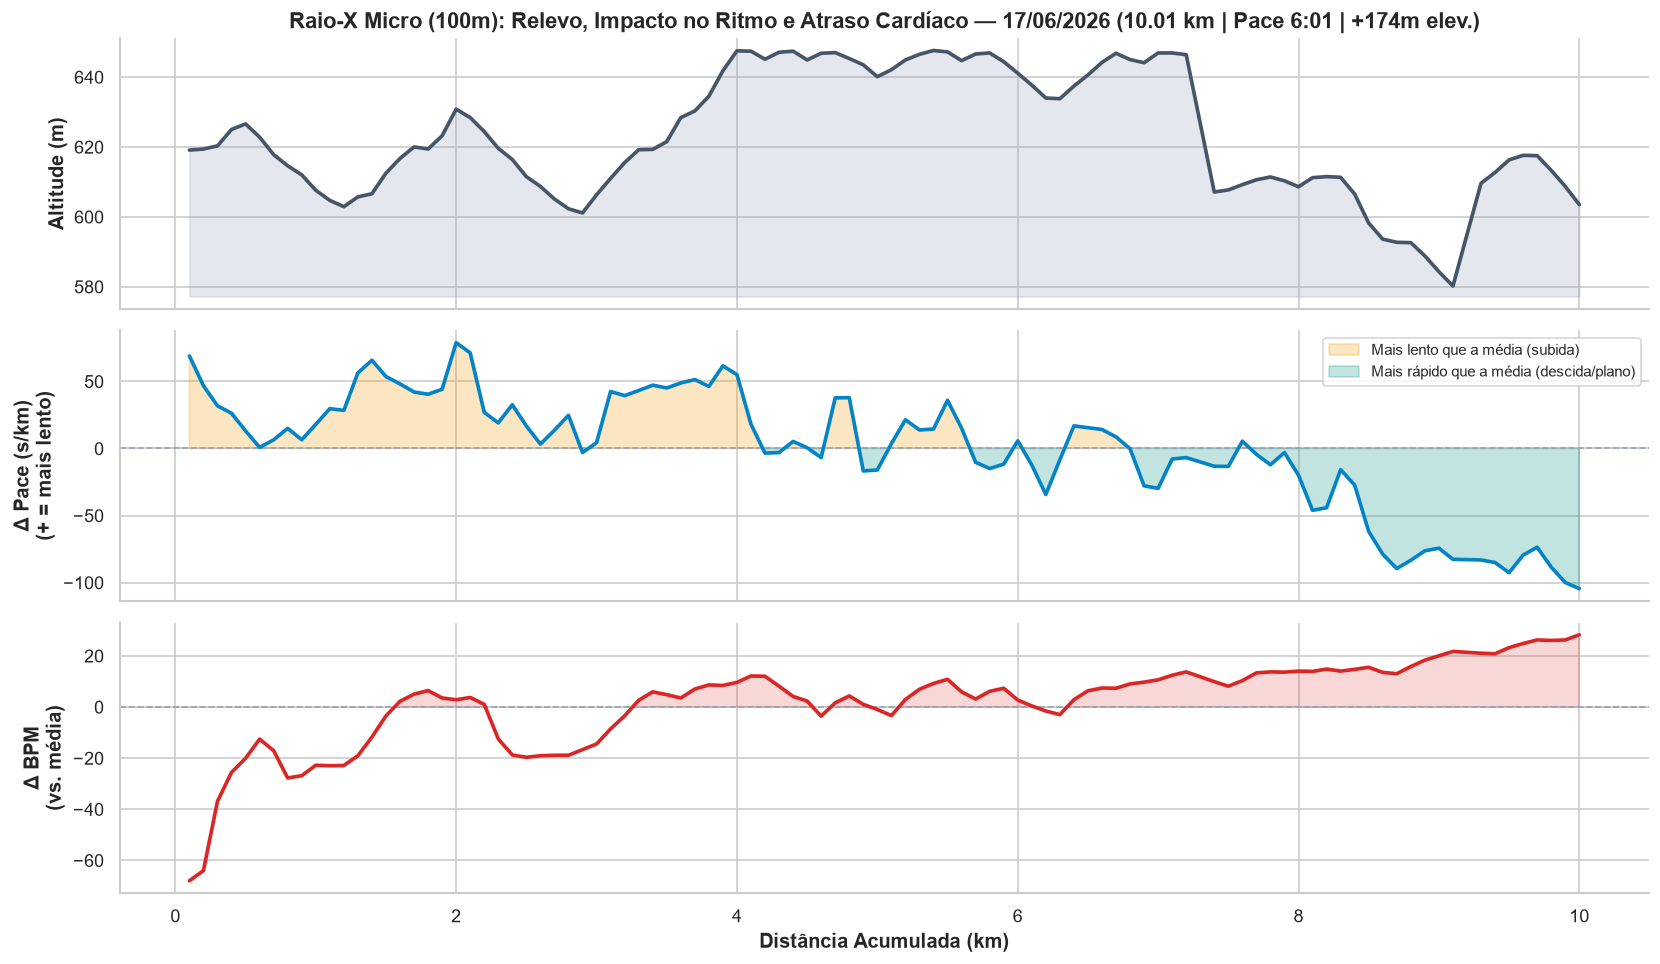

In [13]:
# Escolhe automaticamente uma corrida fechada de 2026 (7K a 10K) com maior ganho de elevação
candidatas_raiox = df_c_validas[
    (df_c_validas["ano"] == 2026)
    & (df_c_validas["faixa_distancia"].isin(["Base 7K", "Base 8K", "Base 10K"]))
].sort_values("ganho_elev_total_m", ascending=False)

treino_exemplo = candidatas_raiox.iloc[0]
rec_exemplo = treino_exemplo["record_id"]

sub_100 = df_100m[df_100m["record_id"] == rec_exemplo].sort_values("dist_acum_m").copy()
sub_100["dist_km_eixo"] = sub_100["dist_acum_m"] / 1000.0
sub_100["delta_pace_smooth"] = (
    sub_100["delta_pace_seg_km"].rolling(2, center=True, min_periods=1).mean()
)

fig, (ax_alt, ax_pace, ax_bpm) = plt.subplots(
    3, 1, figsize=(14, 8.2), sharex=True
)

# 1. Perfil de Altitude
ax_alt.plot(
    sub_100["dist_km_eixo"],
    sub_100["altitude_fim_m"],
    color="#475569",
    linewidth=2.2,
)
ax_alt.fill_between(
    sub_100["dist_km_eixo"],
    sub_100["altitude_fim_m"],
    sub_100["altitude_fim_m"].min() - 3,
    color="#94A3B8",
    alpha=0.25,
)
ax_alt.set_ylabel("Altitude (m)", fontweight="bold")
ax_alt.set_title(
    f"Raio-X Micro (100m): Relevo, Impacto no Ritmo e Atraso Cardíaco — "
    f"{treino_exemplo['data'].strftime('%d/%m/%Y')} ({treino_exemplo['distancia_km']:.2f} km | "
    f"Pace {treino_exemplo['pace_fmt']} | +{treino_exemplo['ganho_elev_total_m']:.0f}m elev.)"
)

# 2. Variação de Pace em relação à média do treino
ax_pace.axhline(0, color="#94A3B8", linestyle="--", linewidth=1)
ax_pace.plot(
    sub_100["dist_km_eixo"],
    sub_100["delta_pace_smooth"],
    color="#0284C7",
    linewidth=2.2,
)
ax_pace.fill_between(
    sub_100["dist_km_eixo"],
    0,
    sub_100["delta_pace_smooth"],
    where=sub_100["delta_pace_smooth"] > 0,
    color="#F59E0B",
    alpha=0.25,
    interpolate=True,
    label="Mais lento que a média (subida)",
)
ax_pace.fill_between(
    sub_100["dist_km_eixo"],
    0,
    sub_100["delta_pace_smooth"],
    where=sub_100["delta_pace_smooth"] <= 0,
    color="#0D9488",
    alpha=0.25,
    interpolate=True,
    label="Mais rápido que a média (descida/plano)",
)
ax_pace.set_ylabel("Δ Pace (s/km)\n(+ = mais lento)", fontweight="bold")
ax_pace.legend(loc="upper right", frameon=True, fontsize=9)

# 3. Variação de BPM em relação à média do treino (evidencia o cardiac lag)
ax_bpm.axhline(0, color="#94A3B8", linestyle="--", linewidth=1)
ax_bpm.plot(
    sub_100["dist_km_eixo"],
    sub_100["delta_bpm"],
    color="#DC2626",
    linewidth=2.2,
)
ax_bpm.fill_between(
    sub_100["dist_km_eixo"],
    0,
    sub_100["delta_bpm"],
    where=sub_100["delta_bpm"] > 0,
    color="#DC2626",
    alpha=0.18,
    interpolate=True,
)
ax_bpm.set_ylabel("Δ BPM\n(vs. média)", fontweight="bold")
ax_bpm.set_xlabel("Distância Acumulada (km)", fontweight="bold")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "07_raio_x_100m_atraso_cardiaco.png")
plt.show()

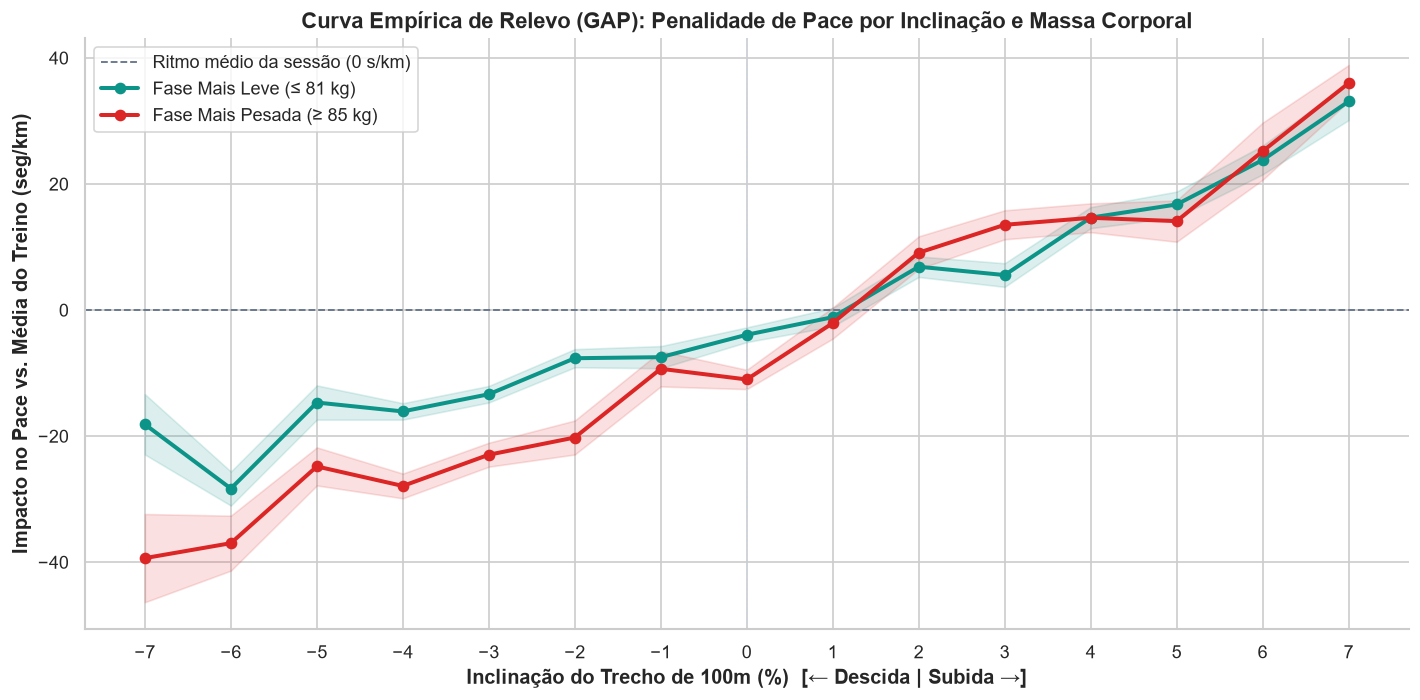

In [14]:
df_inc = df_100m.dropna(subset=["inclinacao_pct", "delta_pace_seg_km", "peso_kg"]).copy()

# Agrupa inclinações inteiras entre -7% e +7% onde há alta densidade de amostras
df_inc["inc_arred"] = df_inc["inclinacao_pct"].round().clip(-7, 7)

df_inc["regime_peso"] = np.select(
    [df_inc["peso_kg"] >= 85.0, df_inc["peso_kg"] <= 81.0],
    ["Fase Mais Pesada (≥ 85 kg)", "Fase Mais Leve (≤ 81 kg)"],
    default="Intermediário (81–85 kg)",
)

sub_regimes = df_inc[
    df_inc["regime_peso"].isin(
        ["Fase Mais Pesada (≥ 85 kg)", "Fase Mais Leve (≤ 81 kg)"]
    )
].copy()

curva_peso = (
    sub_regimes.groupby(["regime_peso", "inc_arred"])
    .agg(
        n=("record_id", "count"),
        delta_pace_medio=("delta_pace_seg_km", "mean"),
        delta_pace_ep=("delta_pace_seg_km", "sem"),
    )
    .reset_index()
    .query("n >= 15")
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.axhline(0, color="#64748B", linestyle="--", linewidth=1.1, label="Ritmo médio da sessão (0 s/km)")
ax.axvline(0, color="#CBD5E1", linestyle=":", linewidth=1.1)

cores_peso = {
    "Fase Mais Pesada (≥ 85 kg)": "#DC2626",
    "Fase Mais Leve (≤ 81 kg)": "#0D9488",
}

for regime, grp in curva_peso.groupby("regime_peso"):
  grp = grp.sort_values("inc_arred")
  ax.plot(
      grp["inc_arred"],
      grp["delta_pace_medio"],
      marker="o",
      linewidth=2.4,
      color=cores_peso[regime],
      label=regime,
  )
  ax.fill_between(
      grp["inc_arred"],
      grp["delta_pace_medio"] - grp["delta_pace_ep"],
      grp["delta_pace_medio"] + grp["delta_pace_ep"],
      color=cores_peso[regime],
      alpha=0.14,
  )

ax.set_xticks(range(-7, 8))
ax.set_xlabel("Inclinação do Trecho de 100m (%)  [← Descida | Subida →]", fontweight="bold")
ax.set_ylabel("Impacto no Pace vs. Média do Treino (seg/km)", fontweight="bold")
ax.set_title(
    "Curva Empírica de Relevo (GAP): Penalidade de Pace por Inclinação e Massa Corporal"
)
ax.legend(frameon=True, loc="upper left")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.savefig(PASTA_IMAGENS / "08_curva_inclinacao_vs_peso.png")
plt.show()

In [15]:
tabela_biomecanica = (
    df_100m.groupby("faixa_inclinacao", observed=True)
    .agg(
        trechos_100m=("record_id", "count"),
        pace_medio_dec=("pace_dec", "mean"),
        delta_pace_seg_km=("delta_pace_seg_km", "mean"),
        bpm_medio=("bpm_medio", "mean"),
        delta_bpm=("delta_bpm", "mean"),
        cadencia_media=("cadencia_media", "mean"),
    )
    .round(2)
)

tabela_biomecanica["pace_medio"] = tabela_biomecanica["pace_medio_dec"].apply(
    fmt_pace_eixo
)

cols_bio = [
    "trechos_100m",
    "pace_medio",
    "delta_pace_seg_km",
    "bpm_medio",
    "delta_bpm",
    "cadencia_media",
]
print("=== IMPACTO BIOMECÂNICO POR FAIXA DE INCLINAÇÃO (TRECHOS DE 100M) ===")
print(tabela_biomecanica[cols_bio].to_string())

=== IMPACTO BIOMECÂNICO POR FAIXA DE INCLINAÇÃO (TRECHOS DE 100M) ===
                               trechos_100m pace_medio  delta_pace_seg_km  bpm_medio  delta_bpm  cadencia_media
faixa_inclinacao                                                                                               
Descida Forte (<-4%)                   1382       6:08             -23.58     152.40       0.06          164.62
Descida Leve (-4% a -1.5%)             2726       6:09             -16.26     151.40      -1.80          164.32
Plano (-1.5% a +1.5%)                  3551       6:11              -4.77     153.57      -1.66          164.05
Subida Leve (+1.5% a +3.5%)            1516       6:34               8.78     157.42       3.84          162.00
Subida Moderada (+3.5% a +6%)          1395       6:43              16.23     157.88       4.85          160.62
Subida Forte (>+6%)                     392       6:59              32.49     159.67       7.30          159.61
